In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df_raw = pd.read_csv("../results/timings.csv")

In [7]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 3645 entries, 0 to 3644
Data columns (total 33 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   session_id          3645 non-null   str    
 1   timestamp_utc       3645 non-null   str    
 2   member              3645 non-null   str    
 3   machine_id          3645 non-null   str    
 4   code_version        3645 non-null   str    
 5   python_version      3645 non-null   str    
 6   os                  3645 non-null   str    
 7   arch                3645 non-null   str    
 8   cpu_model_detected  3645 non-null   str    
 9   cpu_count           3645 non-null   int64  
 10  mem_total_gb        3645 non-null   float64
 11  in_docker           3645 non-null   bool   
 12  pythonhashseed      3645 non-null   int64  
 13  experiment          3645 non-null   str    
 14  dataset             3645 non-null   str    
 15  key_column          3645 non-null   str    
 16  insert_order     

In [18]:
df = df_raw[df_raw['session_id'] == "a2ac476ea8ec"] # filter to experiments session
df = df[df['index_type'] == 'unsorted_list'] # filter to only unsorted index types

## E1

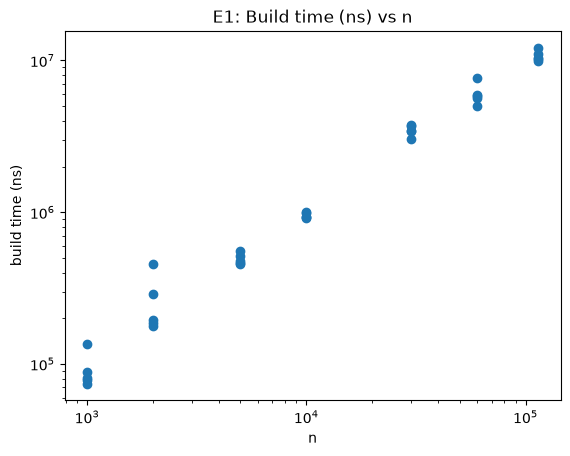

In [35]:
e1 = df[df['experiment'] == 'E1_build_track_id']

plt.loglog(e1['n_keys'], e1['total_ns'], 'o')
plt.xlabel('n')
plt.ylabel('build time (ns)')
plt.title('E1: Build time (ns) vs n')
plt.show()

## E2

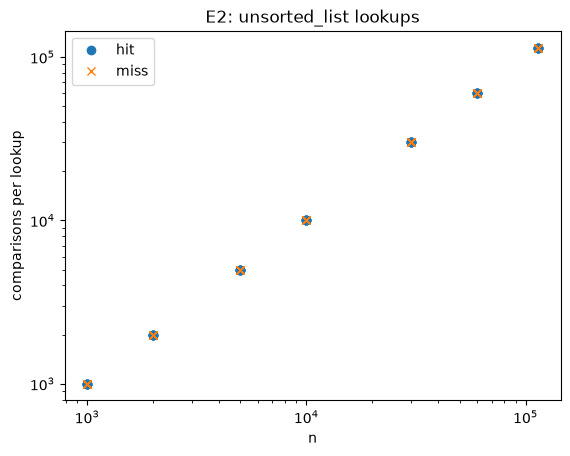

In [36]:
e2 = df[df['experiment'] == 'E2_point_track_id']
hit = e2[e2['operation'] == 'point_hit']
miss = e2[e2['operation'] == 'point_miss']

plt.loglog(hit['n_keys'], hit['comparisons'] / hit['n_ops'], 'o', label='hit')
plt.loglog(miss['n_keys'], miss['comparisons'] / miss['n_ops'], 'x', label='miss')
plt.xlabel('n')
plt.ylabel('comparisons per lookup')
plt.title('E2: unsorted_list lookups')
plt.legend()
plt.show()

## E3

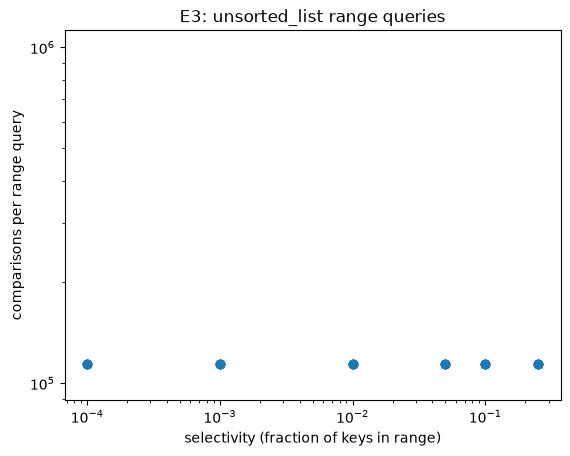

In [37]:
e3 = df[df['experiment'] == 'E3_range_tempo']

plt.loglog(e3['operation_param'], e3['comparisons'] / e3['n_ops'], 'o')
plt.xlabel('selectivity (fraction of keys in range)')
plt.ylabel('comparisons per range query')
plt.title('E3: unsorted_list range queries')
plt.show()

## E4

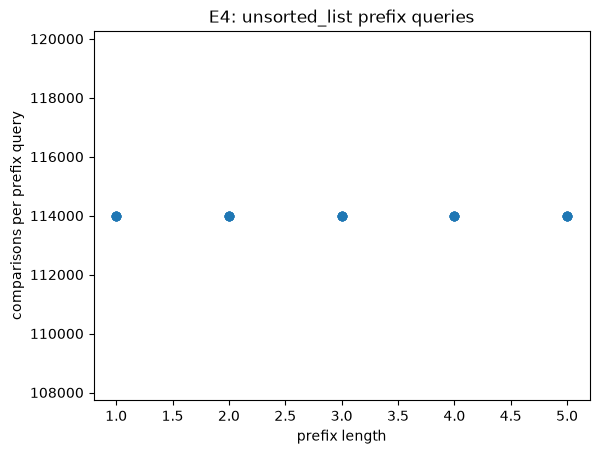

In [38]:
e4 = df[df['experiment'] == 'E4_prefix_track_name']

plt.plot(e4['operation_param'], e4['comparisons'] / e4['n_ops'], 'o')
plt.xlabel('prefix length')
plt.ylabel('comparisons per prefix query')
plt.title('E4: unsorted_list prefix queries')
plt.show()

## E5

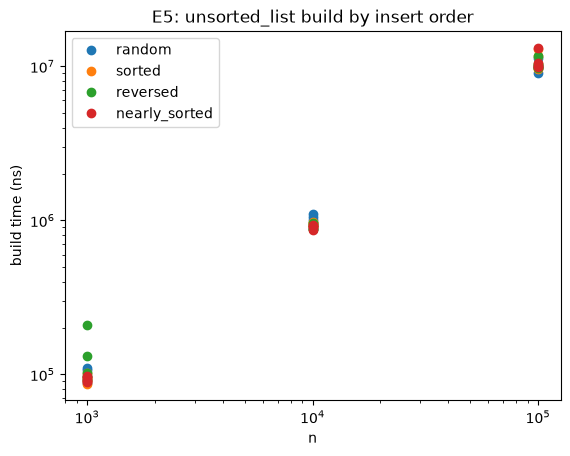

In [39]:
e5 = df[df['experiment'] == 'E5_insert_order']
build = e5[e5['operation'] == 'build']

for order in ['random', 'sorted', 'reversed', 'nearly_sorted']:
    b = build[build['insert_order'] == order]
    plt.loglog(b['n_keys'], b['total_ns'], 'o', label=order)

plt.xlabel('n')
plt.ylabel('build time (ns)')
plt.title('E5: unsorted_list build by insert order')
plt.legend()
plt.show()